In [1]:
# conda env 'vis2_clone'
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats
import xarray as xr

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))


In [2]:
import src.CAMP2Ex as cx
import src.Retrieval as retrieval
from src.ExperimentSet import ExperimentSet
plt.style.use('seaborn-v0_8-paper')

In [3]:
es_dir = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08'
exset = ExperimentSet(es_dir)
exset.set_retrieval_list()
exset.load_retrievals(iteration=-1, extinction_th=[0.3, np.inf])

In [4]:
df_at3d = pd.DataFrame()

for r in list(exset.retrievals.values()):
    tmp_df = r.solvers_retrieval[0.67].medium['cloud'].extinction.to_dataframe()
    tmp_df['source'] = r.exp_name
    df_at3d = pd.concat([df_at3d, tmp_df[tmp_df['extinction'] > 0.3]])

df_at3d = df_at3d.reset_index()
df_at3d['x'] *= 1000
df_at3d['y'] *= 1000
df_at3d['z'] *= 1000

In [5]:
RAW_DATA = PROJECT_ROOT / 'data' / 'raw'
nav_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'CAMP2EX-MetNav_P3B_20191001_R0.ict'
fcdp_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-FCDP_P3B_20191001_R1.ict'
tds_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-2DS10_P3B_20191001_R0.ict'
df_p3 = cx.load_FCDP_2DS(fcdp_file, tds_file, nav_file, breakpoint=40, resample='2s')
df_p3['source'] = 'in situ'

/data/gdi/b/johntl3/LundstromPub2025/src/CAMP2Ex.py:110: RuntimeWarning: invalid value encountered in divide
  Re = np.sum(n * r**3, axis=-1) / np.sum(n * r**2, axis=-1)


In [6]:
# bins = np.arange(350, 1251, 100)
bins = np.arange(-50, 1451, 100)
df_at3d['altitude_bin'] = pd.cut(df_at3d['z'], bins=bins)
df_p3['altitude_bin'] = pd.cut(df_p3['GPS_Altitude'], bins=bins)

In [7]:
start_time = pd.to_datetime('2019-10-02 00:00:00')
end_time = pd.to_datetime('2019-10-02 02:00:00')

df_p3_sub = df_p3[
    # (p3['N_L'] > 10000)
    (df_p3['ext_km'] > 0.3)
    & (df_p3.index > start_time)
    & (df_p3.index < end_time)
    & (df_p3['GPS_Altitude'] < 1250)
    # & (p3['optical_path'] < 5)       # Remove P3 veiled core
    # & (p3['pass_length'] < 3600)
    & ~(
        ((df_p3.index >= pd.to_datetime('2019-10-02 00:35:00')) & (df_p3.index <= pd.to_datetime('2019-10-02 00:36:00')))
        | ((df_p3.index >= pd.to_datetime('2019-10-02 01:45:00')) & (df_p3.index <= pd.to_datetime('2019-10-02 01:46:30')))
    )
]
df_p3_sub = df_p3_sub.reset_index().rename(columns={'ext_km':'extinction'})

In [8]:
df_p3_at3d = pd.concat([
    df_at3d.loc[:, ['extinction', 'altitude_bin', 'source']],
    df_p3_sub.loc[:, ['extinction', 'altitude_bin', 'source']] #.groupby('altitude_bin').filter(lambda x: len(x) > 10)
])

In [9]:
for i, name in enumerate(exset.retrievals.keys()):
    print(f'{i}: {name}')

0: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/LCL_CTH
1: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/unconstrained
2: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/unconstrained_darksurf
3: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/unconstrained_mod
4: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/HBC/periodic
5: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/0p150
6: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/0p250
7: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/mix22
8: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/mix54
9: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/cloud_motion/fast
10: /data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/cloud_motion/fast_unconstrained
11: /data/gdi/b/johntl3/LundstromPub2025/e

/tmp/ipykernel_3031858/1360304948.py:26: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sample_counts = df_p3_at3d.groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)


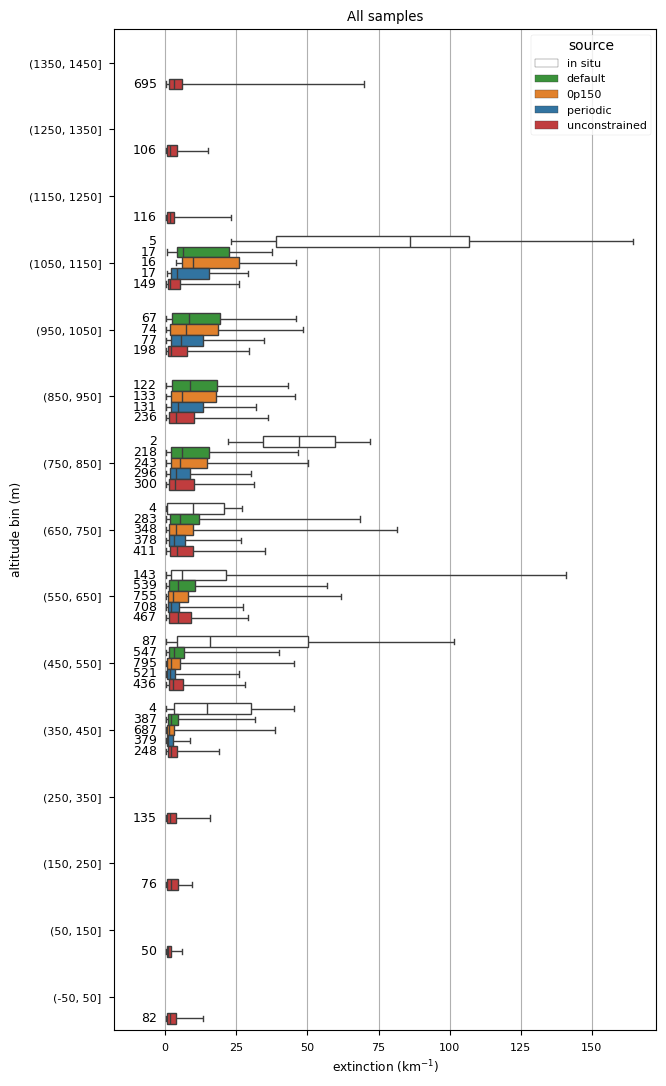

In [10]:
pltlist = ['in situ', 'default', '0p150', 'periodic', 'unconstrained']
# pltlist = ['in situ', 'default', '0p150']

box_kwargs = {
    'x': 'extinction',
    'y': 'altitude_bin',
    'hue': 'source',
    'hue_order': pltlist,
    'palette': {
        'in situ': 'white',
        'default': 'tab:green',
        'periodic': 'tab:blue',
        'unconstrained': 'tab:red',
        '0p150': 'tab:orange'
    },
    'order': [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)],
    'whis':(0, 100),
}

f, ax = plt.subplots(1, 1, figsize=(7,13), sharex=False, sharey=True)
sns.boxplot(df_p3_at3d[df_p3_at3d['source'].isin(pltlist)], ax=ax, **box_kwargs)

# Add sample count annotations
altitude_order = [f'({bins[i]}, {bins[i+1]}]' for i in range(len(bins) - 2, -1, -1)]
sources = pltlist
sample_counts = df_p3_at3d.groupby(['altitude_bin', 'source']).size().unstack(fill_value=0)

# Convert categorical index to string for comparison
sample_counts.index = sample_counts.index.astype(str)

for i, altitude in enumerate(altitude_order):
    if altitude in sample_counts.index:
        for j, source in enumerate(sources):
            if source in sample_counts.columns:
                count = sample_counts.loc[altitude, source]
                if count > 0:
                    # Position text to the left of each box
                    y_pos = i + (j - len(sources)/2 + 0.5) * 0.8 / len(sources)
                    ax.text(-3, y_pos, f'{count}', ha='right', va='center', fontsize=9)

ax.set_xlim(-18, None)
ax.set_ylabel('altitude bin (m)')
ax.set_xlabel(r'extinction (km$^{-1}$)')
ax.set_title('All samples')
ax.grid(axis='x')